<a href="https://colab.research.google.com/github/NikKimo/teaching/blob/main/simulation_geoffreys_bus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Load packages

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set number of simulations

In [18]:
n = 2000

# Simulate Geoffrey's arrival at the bus stop

Mean = −2 minutes, SD = 2 minutes.

In [19]:
arrival_at_bus_stop = np.random.normal(-2, 2, n)

In [20]:
pd.DataFrame({'arrival_at_bus_stop': arrival_at_bus_stop})

,arrival_at_bus_stop
0,-0.571029
1,1.250099
2,-5.037706
3,-0.162544
4,-3.102508
...,...
1995,-1.250346
1996,-4.122382
1997,3.186210
1998,-1.665076


# Simulate bus departure times

First bus: Mean = 0, SD = 1.

Second bus: Mean = 20, SD = 1.

In [21]:
arrival_of_bus1 = np.random.normal(0, 1, n)
arrival_of_bus2 = np.random.normal(20, 1, n)

In [22]:
pd.DataFrame({'arrival_of_bus1': arrival_of_bus1, 'arrival_of_bus2': arrival_of_bus2})

,arrival_of_bus1,arrival_of_bus2
0,-1.985143,19.714144
1,0.528907,19.983675
2,1.792094,19.057014
3,-0.434591,18.769850
4,-1.168507,20.488948
...,...,...
1995,-2.462837,22.232406
1996,0.417949,20.461748
1997,1.850220,19.727480
1998,-1.235131,20.352815


# Simulate travel times

Mean = 30 minutes, SD = 5 minutes.

In [23]:
travel_time_bus1 = np.random.normal(30, 5, n)
travel_time_bus2 = np.random.normal(30, 5, n)

In [24]:
pd.DataFrame({'travel_time_bus1': travel_time_bus1, 'travel_time_bus2': travel_time_bus2})

,travel_time_bus1,travel_time_bus2
0,19.853385,27.551171
1,34.256561,29.525260
2,28.571887,26.026736
3,31.870749,26.245798
4,36.611460,33.862943
...,...,...
1995,32.141123,40.873664
1996,21.681467,29.936304
1997,25.640592,31.351860
1998,29.106551,25.396009


# Determine which bus Geoffrey catches

In [25]:
pd.DataFrame({'arrival_of_bus1': arrival_of_bus1, 'travel_time_bus1': travel_time_bus1, 'arrival_of_bus2': arrival_of_bus2, 'travel_time_bus2': travel_time_bus2})

,arrival_of_bus1,travel_time_bus1,arrival_of_bus2,travel_time_bus2
0,-1.985143,19.853385,19.714144,27.551171
1,0.528907,34.256561,19.983675,29.525260
2,1.792094,28.571887,19.057014,26.026736
3,-0.434591,31.870749,18.769850,26.245798
4,-1.168507,36.611460,20.488948,33.862943
...,...,...,...,...
1995,-2.462837,32.141123,22.232406,40.873664
1996,0.417949,21.681467,20.461748,29.936304
1997,1.850220,25.640592,19.727480,31.351860
1998,-1.235131,29.106551,20.352815,25.396009


If Geoffrey arrives before the first bus departs, he catches it. Otherwise, he takes the second bus.

arrival <= bus1 checks whether Geoffrey arrives at the bus stop before or when the first bus departs.



bus1 + travel1 calculates university arrival time if the condition is TRUE.



bus2 + travel2 calculates university arrival time if the condition is FALSE.

In [26]:
journey_time = np.where(
    arrival_at_bus_stop <= arrival_of_bus1,
    arrival_of_bus1 + travel_time_bus1,
    arrival_of_bus2 + travel_time_bus2
)

In [27]:
pd.DataFrame({'arrival_of_bus1': arrival_of_bus1, 'travel_time_bus1': travel_time_bus1, 'arrival_of_bus2': arrival_of_bus2, 'travel_time_bus2': travel_time_bus2, 'journey_time': journey_time})

,arrival_of_bus1,travel_time_bus1,arrival_of_bus2,travel_time_bus2,journey_time
0,-1.985143,19.853385,19.714144,27.551171,47.265315
1,0.528907,34.256561,19.983675,29.525260,49.508936
2,1.792094,28.571887,19.057014,26.026736,30.363982
3,-0.434591,31.870749,18.769850,26.245798,45.015647
4,-1.168507,36.611460,20.488948,33.862943,35.442953
...,...,...,...,...,...
1995,-2.462837,32.141123,22.232406,40.873664,63.106070
1996,0.417949,21.681467,20.461748,29.936304,22.099417
1997,1.850220,25.640592,19.727480,31.351860,51.079340
1998,-1.235131,29.106551,20.352815,25.396009,27.871420


# Calculate average arrival time

In [28]:
np.mean(journey_time)

np.float64(33.52114742896886)

# Plot the histogram

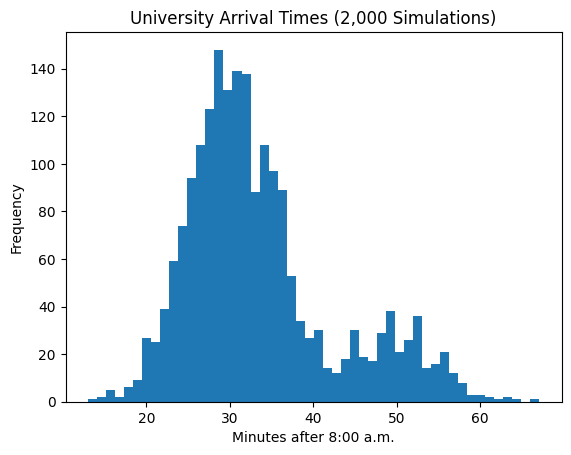

In [31]:
plt.hist(journey_time, bins=50)
plt.xlabel("Minutes after 8:00 a.m.")
plt.ylabel("Frequency")
plt.title("University Arrival Times (2,000 Simulations)")
plt.show()

University arrival times do not follow a normal distribution because they depend on which bus Geoffrey catches.